# Deep neural network in PyTorch: cat vs non-cat

The same L-layer ReLU network as in the NumPy lab, built with `nn.Sequential`.
One class covers any depth (`[n_x, 4, 1]` is shallow, `[n_x, 20, 7, 5, 1]` is deep).
Experiments: verification against the NumPy implementation, depth, initialization, SGD vs Adam.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from data import (
    flatten_and_normalize,
    load_cifar10_cat_vs_rest,
    load_h5_dataset,
    to_tensors,
)
from model import DeepNetworkTorch, accuracy, load_numpy_reference, set_seed, train

In [4]:
SEED = 1
DATA_SOURCE = "h5"  # "h5" (local files in data/) or "cifar10" (downloaded automatically)

LOCAL_DATA = Path("data")
DRIVE_DATA = Path("/content/drive/MyDrive/data/01-foundations/logistic-regression")

DATA_DIR = DRIVE_DATA if DRIVE_DATA.exists() else LOCAL_DATA
print("Using data from:", DATA_DIR.resolve())

DRIVE_ASSETS = Path("/content/drive/MyDrive/data/01-foundations/deep-network/assets")
LOCAL_ASSETS = Path("../assets")   # for local machine

ASSETS = DRIVE_ASSETS if Path("/content/drive/MyDrive").exists() else LOCAL_ASSETS
ASSETS.mkdir(parents=True, exist_ok=True)
print("Saving assets to:", ASSETS.resolve())

Using data from: /Users/iharharkusha/Documents/nyawmolny/deep-learning-fundamentals/01-foundations/deep-network/pytorch/data
Saving assets to: /Users/iharharkusha/Documents/nyawmolny/deep-learning-fundamentals/01-foundations/deep-network/assets


## 1. Data

In [6]:
if DATA_SOURCE == "h5":
    x_train_img, y_train_np, x_test_img, y_test_np = load_h5_dataset(
        str(DATA_DIR / "train_catvnoncat.h5"),
        str(DATA_DIR / "test_catvnoncat.h5"),
    )
else:
    x_train_img, y_train_np, x_test_img, y_test_np = load_cifar10_cat_vs_rest()

X_train_np = flatten_and_normalize(x_train_img)
X_test_np = flatten_and_normalize(x_test_img)
X_train, y_train = to_tensors(X_train_np, y_train_np)
X_test, y_test = to_tensors(X_test_np, y_test_np)

n_x = X_train.shape[1]
print("X_train:", tuple(X_train.shape), "| X_test:", tuple(X_test.shape))
print("positive rate train/test:", y_train_np.mean().round(3), y_test_np.mean().round(3))

X_train: (209, 12288) | X_test: (50, 12288)
positive rate train/test: 0.344 0.66


## 2. Verification against the NumPy implementation

Same initial weights (copied from the NumPy model), same data, full batch, float64.
Forward pass, gradients and the loss curve must coincide.

In [7]:
ref = load_numpy_reference()
dims = [n_x, 20, 7, 5, 1]
LR, EPOCHS = 0.0075, 200

np_params = ref.initialize_parameters(dims, "he", seed=SEED)
AL, caches = ref.forward_propagation(X_train_np.T, np_params)
np_grads = ref.backward_propagation(AL, y_train_np.reshape(1, -1), caches)
np_net = ref.DeepNetwork(dims, learning_rate=LR, num_iterations=EPOCHS, init="he",
                         seed=SEED, log_every=1).fit(X_train_np.T, y_train_np.reshape(1, -1))

X64, y64 = to_tensors(X_train_np, y_train_np, dtype=torch.float64)
t_model = DeepNetworkTorch(dims).double()
t_model.load_numpy_params(np_params)

probs = t_model.predict_proba(X64).detach().numpy().T
t_model_loss = torch.nn.BCEWithLogitsLoss()(t_model(X64), y64)
t_model_loss.backward()
grad_diff = max(
    np.abs(layer.weight.grad.numpy() - np_grads[f"dW{l}"]).max()
    for l, layer in enumerate(t_model.linears, start=1)
)
t_train_model = DeepNetworkTorch(dims).double()
t_train_model.load_numpy_params(np_params)
t_losses = train(t_train_model, X64, y64,
                 torch.optim.SGD(t_train_model.parameters(), lr=LR), EPOCHS)

print("max |forward difference| :", np.abs(probs - AL).max())
print("max |gradient difference|:", grad_diff)
print("max |loss difference|    :", np.max(np.abs(np.array(t_losses) - np.array(np_net.costs_))))

max |forward difference| : 1.887379141862766e-15
max |gradient difference|: 8.326672684688674e-17
max |loss difference|    : 6.661338147750939e-16


## 3. Depth (SGD, lr=0.0075, 2500 epochs, He init)

2-layer: train=100.0%  test=70.0%
4-layer: train=100.0%  test=80.0%
6-layer: train=100.0%  test=62.0%


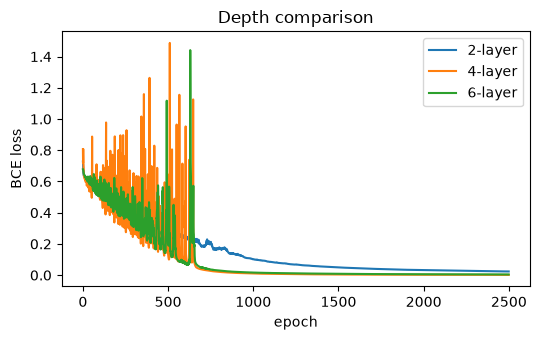

In [8]:
def run(dims, init="he", lr=0.0075, num_epochs=2500):
    set_seed(SEED)
    model = DeepNetworkTorch(dims, init=init)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    losses = train(model, X_train, y_train, opt, num_epochs)
    return model, losses


configs = {
    "2-layer": [n_x, 7, 1],
    "4-layer": [n_x, 20, 7, 5, 1],
    "6-layer": [n_x, 30, 20, 12, 7, 5, 1],
}
plt.figure(figsize=(5.5, 3.5))
for name, d in configs.items():
    model, losses = run(d)
    plt.plot(losses, label=name)
    print(f"{name}: train={accuracy(model, X_train, y_train):.1%}  test={accuracy(model, X_test, y_test):.1%}")
plt.xlabel("epoch")
plt.ylabel("BCE loss")
plt.legend()
plt.title("Depth comparison")
plt.tight_layout()
plt.savefig(ASSETS / "torch_depth_comparison.png", dpi=150)
plt.show()

## 4. Initialization: N(0, 0.01^2) vs He (6-layer)

init=small  final loss=0.6440  train=65.6%  test=34.0%
init=he     final loss=0.0045  train=100.0%  test=62.0%


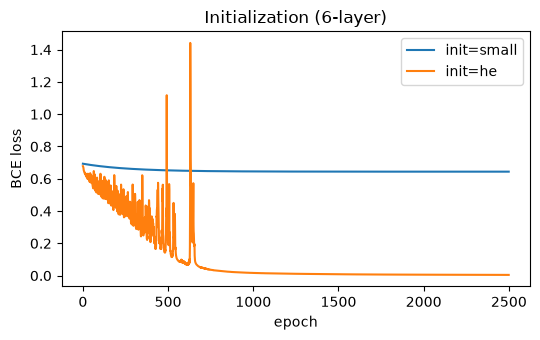

In [9]:
plt.figure(figsize=(5.5, 3.5))
for init in ["small", "he"]:
    model, losses = run(configs["6-layer"], init=init)
    plt.plot(losses, label=f"init={init}")
    print(f"init={init:<6} final loss={losses[-1]:.4f}  train={accuracy(model, X_train, y_train):.1%}  test={accuracy(model, X_test, y_test):.1%}")
plt.xlabel("epoch")
plt.ylabel("BCE loss")
plt.legend()
plt.title("Initialization (6-layer)")
plt.tight_layout()
plt.savefig(ASSETS / "torch_init_comparison.png", dpi=150)
plt.show()

## 5. Results and notes

- **NumPy vs PyTorch:** with identical weights the two agree to float64 machine precision — max forward diff 1.9e-15, max gradient diff 8.3e-17, max loss diff 6.7e-16. Hand-written forward/backward are correct.
- **Depth vs test accuracy:** all configurations reach 100% train accuracy; test accuracy
  is 70% (2 layers), 80% (4 layers) and 62% (6 layers). With 50 test images one image is
  2 pp, so these differences are 5 and 9 images. The NumPy lab, run on the same data with a
  different random initialization, gave 72%, 74% and 76% for the same three depths, a
  different ordering. So the depth effect is not reliable here: the results swing by about
  ±10 pp with the initialization and the small test set. A likely contributor to the drop at
  6 layers is stronger overfitting of a larger model to 209 images, but I did not test this.
- **Small vs He initialization:** with N(0, 0.01²) the 6-layer network stalls at loss 0.644,
  which equals the entropy of the label distribution, and predicts "non-cat" for every
  image (train 65.6%, test 34.0% = class proportions). He initialization trains normally
  (loss 0.0045, 100% train), so initialization decides whether the signal and gradients
  survive through depth. Its test accuracy (62%) is still lower than the 4-layer network's,
  for the reasons above.
- **Agreement with the NumPy lab:** the small-initialization failure is identical
  (loss 0.644, 65.6% / 34.0%); the He test accuracies differ (62% here, 76% there), which
  again points to initialization and test-set noise rather than a framework difference.